# **Python for Neuro:** Week 5

Today, we'll review functions and learn how to use numpy!

# Cool tangent: F strings

F strings allow you to format specific parts of strings. It's always a great tool for debugging or generating readable function outputs.

Some cool f string examples below:

In [1]:
txt = f"The price is 49 dollars"  # This is an f-string, but we did not format it
print(txt)

The price is 49 dollars


In [2]:
price = 59

txt = f"The price is {price} dollars"  # This is a formatted f-string. The area inside {} is called a placeholder
print(txt)

The price is 59 dollars


You can also modify your variable inside the f string placeholder. for example, convert it to a 2 decimal point float.

In [3]:
price = 59
txt = f"The price is {price:.2f} dollars"  # : means format the placeholder, and .2f means format as a float with 2 decimal places
print(txt)

The price is 59.00 dollars


We could even do math inside the placeholder

In [4]:
price = 59
txt = f"The price is {2 * price + 10} dollars"  # : means format the placeholder, and .2f means format as a float with 2 decimal places
print(txt)

The price is 128 dollars


More examples can be found at
https://www.w3schools.com/python/python_string_formatting.asp

## Numpy!

Often times, we want to work with collectons of data. The simplest rendition of this is a list:

In [5]:
lst_1 = [25, 20, 40, 5]

But these lists are missing a lot of functionality that we find useful for handling numerical data. (You may be used to these from Matlab or R.) For example, suppose you want to multiply each number by 2. We may want the following command to work:

In [6]:
2*lst_1

[25, 20, 40, 5, 25, 20, 40, 5]

Yet its output is not what we are looking for. This is because lists are not *vectorized*: they do not assume that operations should be applied elementwise. Instead we would have to use a command like the one below:

In [7]:
lst_2 = [lst_1[i]*2 for i in range(4)]
lst_2

[50, 40, 80, 10]

To address this and other issue that arise in handling numerical data in Python, we can use `numpy`, which stands for numerical data in Python.

So far, we have exclusively used Python's base functionality. `numpy` is the first example of a package that has been contributed by external users and has to be installed manually. It is, however, integral to Python for basically anyone working with numerical data.

In [1]:
import numpy as np

## One-dimensional arrays: Vectors
The central object of interest for numpy is an *array*, which refers to rectangular data (more on this later). The simplest case of an array is a one-dimensional one, a vector. You can create a vector from a list:

In [9]:
lst_1 = [25, 20, 40, 5]
vec_1 = np.array(lst_1)

In [10]:
vec_1

array([25, 20, 40,  5])

In [11]:
type(vec_1)

numpy.ndarray

We can also turn a vector back into a list:

In [13]:
list(vec_1)

[np.int64(25), np.int64(20), np.int64(40), np.int64(5)]

Using the numpy array, we can now perform mathematical operations in the way we would like (and perhaps expect from e.g. Matlab).

In [14]:
vec_2 = 2*vec_1
vec_2

array([50, 40, 80, 10])

In [15]:
vec_1+vec_2

array([ 75,  60, 120,  15])

In contrast, what happens if we add two lists?

In [16]:
lst_1 + lst_2

[25, 20, 40, 5, 50, 40, 80, 10]

### Differences between lists and vectors
Both lists and vectors can be indexed and we can easily transform an array into a list and vice versa. What are some of their differences?
#### Elementwise operations
We have already covered that arrays have elementwise operations whereas lists do not.
#### Each element must have the same type
Lists can consist of elements with different types:

In [17]:
lst_3 = ['a', 5]
lst_3

['a', 5]

An array, on the other hand, will always have the same data type for each of its elements. If a list with unequal types is converted to an array all its elements are converted to the same data type.

In [18]:
vec_3 = np.array(lst_3)
vec_3

array(['a', '5'], dtype='<U21')

<U21 is the data type corresponding to strings. You usually don't want to rely on this automatic casting functionality and should try to avoid it.

In [19]:
type(vec_3)

numpy.ndarray

How can you print out the type of this vector? Note that `type(vec_3)` gives you the type of the entire object which is a numpy array. Rather you want the type of the individual elements. Try using the autocomplete function to find out.

*Hint* look at what the type information was called above.

In [20]:
vec_3.dtype

dtype('<U21')

In [21]:
vec_1.dtype

dtype('int64')

You can also reassign data types 

In [22]:
vec_1.astype(np.float16)    # Numpy's 16bit float dtype

array([25., 20., 40.,  5.], dtype=float16)

In [23]:
vec_1.dtype

dtype('int64')

We do we not need parentheses after `dtype`? This is because `dtype` is not function, but rather a new type of Python object called an *attribute*. These are like variables, but are limited in scope to specific objects. We will get to know them in more depth in a later lesson.

### Question 1

- Create a numpy array with the elements 3, 7, 10 and divide each element by two
- Create a new array `vec_4` that is the elementwise multiplication of `vec_1` and `vec_2`.
- Create an array `vec_5` that has a `True` value wherever `vec_1` is smaller than or equal to `20` and a `False` value otherwise. *Hint:* This should be possible in a one liner.

In [24]:
new_array = np.array([3,7,10])
new_array / 2

array([1.5, 3.5, 5. ])

In [25]:
vec_4  = vec_1 * vec_2
vec_4

array([1250,  800, 3200,   50])

In [26]:
vec_5 = vec_1 <= 20
vec_5

array([False,  True, False,  True])

## Two-dimensional arrays: Matrices
Rectangular data in two dimensions is often called a matrix: it consists of observations organized by rows and columns. Basic Python would allow us to store such data using a list of lists:

In [27]:
lst_1 = [
    [1, 2],
    [3, 4],
    [5, 6]
]
lst_1

[[1, 2], [3, 4], [5, 6]]

Yet the already tedious process of computing elementwise operations quickly becomes infeasible in this context. If wanted to multiply each element by two we would have to iterate over the outer list and then the inner set of lists.

In [28]:
lst_2 = [
    [2*it2 for it2 in it] for it in lst_1
]
lst_2

[[2, 4], [6, 8], [10, 12]]

Again we can turn the list of lists into a matrix simply by applying `np.array`:

In [29]:
mat_1 = np.array(lst_1)
mat_1

array([[1, 2],
       [3, 4],
       [5, 6]])

Now we can apply vectorized operations as previously:

In [30]:
mat_2 = 2*mat_1
mat_2

array([[ 2,  4],
       [ 6,  8],
       [10, 12]])

How can you find out the number of rows and columns of the matrix? Try googling or exploring the methods using the autocomplete function.

In [31]:
mat_1.shape

(3, 2)

Importantly, numpy, by default, uses elementwise computations. So `*` results in elementwise multiplication, not matrix multiplication.

In [32]:
mat_1*mat_2

array([[ 2,  8],
       [18, 32],
       [50, 72]])

You can run matrix multiplication by using the `@` operator.

In [33]:
mat_3 = np.array([[1,2],[3,4]])
mat_1@mat_3

array([[ 7, 10],
       [15, 22],
       [23, 34]])

### Saving arrays
We can save arrays using `np.save`.

In [34]:
np.save('mat_1.npy', mat_1)

In [35]:
mat_1_copy = np.load('mat_1.npy')

In [36]:
mat_1_copy

array([[1, 2],
       [3, 4],
       [5, 6]])

## Higher-dimensional arrays

We now load some simulated data, which is stored in the file `ex_array.npy`. Try assigning the data in that file to the variable `arr`.

In [2]:
arr = np.load('ex_array.npy')

Suppose you know that what is stored in this data are spike rates of fifty different neurons for two different conditions and ten repeated measurements. Spike rates are recorded every second for 2000 seconds. How can you figure out how this data is represented in the array?

In [38]:
arr.shape

(2, 10, 50, 2000)

In [39]:
arr.ndim

4

Whereas a vector has one dimension and a matrix has two dimensions, `arr` has four dimensions: the first one specifies the condition, the second one the trial, the third one the neuron, and the fourth one the timepoint. We can also create higher-dimensional arrays directly:

In [40]:
arr_2 = np.array([
    [[2,4,6],
     [1,3,5]],
    [[0.5,1,2],
     [0.75, 1, 1.25]]
])

What is `arr_2.ndim` and `arr_2.shape`?

In [41]:
arr_2.ndim

3

In [42]:
arr_2.shape

(2, 2, 3)

### Data must be rectangular
Importantly numpy only allows for rectangular data. What happens if you create an array from a list of lists with unequal length?

In [43]:
mat = np.array([[1,2],[3]])

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [44]:
mat

NameError: name 'mat' is not defined

### Broadcasting

In general you cannot add two matrices with different shapes:

In [45]:
mat_1.shape

(3, 2)

In [46]:
mat_3 = np.array([
    [1,2,3],
    [1,2,3]
])

In [47]:
mat_1+mat_3

ValueError: operands could not be broadcast together with shapes (3,2) (2,3) 

Elementwise operations can work between two arrays with unequal shapes:
- If they match everywhere except where one of them has a dimension of length 1
- If they have an unequal number of dimensions, the array with fewer dimensions is appended dimensions of length 1 in the beginning.

In [48]:
np.array([
    [1,2]
]) + np.array([
    [1,2],
    [3,4],
    [5,6]
])

array([[2, 4],
       [4, 6],
       [6, 8]])

The same thing is true for matrices with one column or other elementwise operations.

In [49]:
divisor =  np.array([2, 1, 1])
divisor.shape

(3,)

In [50]:
mat_1 / divisor

ValueError: operands could not be broadcast together with shapes (3,2) (3,) 

In [51]:
mat_1

array([[1, 2],
       [3, 4],
       [5, 6]])

In [52]:
divisor = divisor[:, np.newaxis]   # [:, None] will also work here
print(f"Shape = {divisor.shape}")
print(divisor)

Shape = (3, 1)
[[2]
 [1]
 [1]]


In [53]:
divisor.shape == np.array([[2], 
                           [1], 
                           [1]]).shape

True

In [54]:
print(mat_1)
mat_1 / divisor

[[1 2]
 [3 4]
 [5 6]]


array([[0.5, 1. ],
       [3. , 4. ],
       [5. , 6. ]])

In [55]:
vec_4 = np.array([1, 2])

In [56]:
vec_4.shape

(2,)

In [57]:
vec_4+mat_1

array([[2, 4],
       [4, 6],
       [6, 8]])

### Creating some arrays

In [58]:
np.linspace(0, 1, 21)

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [59]:
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [60]:
np.arange(1, 10, 2)

array([1, 3, 5, 7, 9])

In [61]:
np.ones((4, 2, 3))

array([[[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]]])

In [62]:
a = np.arange(1, 10, 2)
np.ones_like(a)

array([1, 1, 1, 1, 1])

### Question 2

Below we're creating arrays with different shapes. Try predicting for each if elementwise addition would work, what shape the resulting array would have, then try it out and see if you were correct.

In [63]:
arr_1 = np.ones((3,2))
arr_2 = np.ones((2,3))

In [71]:
arr_1 + arr_2

array([[[2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.]],

       [[2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.]],

       [[2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.]],

       [[2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.],
        [2., 2., 2., 2., 2.]]])

In [67]:
arr_1 = np.ones((4,1,5))
arr_2 = np.ones((4,6,5))

In [66]:
arr_1 = np.ones((4,1,5))
arr_2 = np.ones((4,6,1))

In [69]:
arr_1 = np.ones((4,3,5))
arr_2 = np.ones((3,5))

In [70]:
arr_1 = np.ones((4,3,5))
arr_2 = np.ones((4,3,1))

## Summary operations

Summary operations allow you to collapse an array according to a certain summary statistic. For instance, we may want to compute the overall mean firing rate in our experimental data:

In [72]:
arr.mean()

np.float64(0.8717270073789575)

You can also specify the axis along we want to average. For instance, maybe we want to average firing rates across individual trials:

In [73]:
arr.shape  # (cond, rep, neuron, timepoint)

(2, 10, 50, 2000)

In [74]:
arr_across_trials = arr.mean(axis=1)

In [75]:
arr_across_trials.shape

(2, 50, 2000)

The `keepdims` argument means that you don't remove the dimensions you're averaging over, but rather set their length to 1:

In [76]:
arr_across_trials = arr.mean(axis=1, keepdims=True)

In [77]:
arr_across_trials.shape

(2, 1, 50, 2000)

You can average across multiple axes as well. For instance, maybe you want to average across both trials and time:

In [78]:
arr_across_trials_and_time = arr.mean(axis=(1,3))

In [79]:
arr_across_trials_and_time.shape

(2, 50)

### Question 3

- What is the average firing rate across all neurons, times, and trials for each condition?
- (Advanced.) Subtract the average firing rate per time across all neurons, trials, and conditions from the original array.

In [81]:
arr.shape  # (cond, rep, neuron, timepoint)
avg_cond = arr.mean(axis=(1,2,3))
print(avg_cond)

[0.98828779 0.75516623]


In [83]:
mean_subtracted = arr - arr.mean(axis=(0,1,2))
print(arr.mean(axis=(0,1,2)).shape)
print(mean_subtracted.shape)

(2000,)
(2, 10, 50, 2000)


## Indexing

Indexing in vectors works just as in lists:

In [85]:
vec_1

array([25, 20, 40,  5])

In [86]:
vec_1[0]

np.int64(25)

For matrices and higher-dimensional arrays, a single index selects a single row:

In [87]:
mat_1

array([[1, 2],
       [3, 4],
       [5, 6]])

In [88]:
mat_1[0]

array([1, 2])

In [89]:
mat_1[0][1]

np.int64(2)

Instead of using two brackets, you can also separate the row and column index by a comma:

In [90]:
# The following two lines of code are equivalent
print(mat_1[0][0])
print(mat_1[0,0])

1
1


### Slicing

Slicing is a useful way of extracting more than one element. In particular, `j:k` extracts the elements j,...,k-1:

In [91]:
vec = np.arange(10)
print(vec)

[0 1 2 3 4 5 6 7 8 9]


In [92]:
vec[3:7]

array([3, 4, 5, 6])

We can leave either end of the range away and it will default to the beginning and the end of the list, respectively.

In [93]:
vec[:7]

array([0, 1, 2, 3, 4, 5, 6])

In [94]:
vec[3:]

array([3, 4, 5, 6, 7, 8, 9])

In [95]:
vec[:] # What do you think this will do?

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

You can therefore also use the colon to select all rows of a matrix and specific columns.

In [96]:
mat_1

array([[1, 2],
       [3, 4],
       [5, 6]])

In [97]:
mat_1[:,0]

array([1, 3, 5])

You can add another colon to specify a step size, similarly to how you would use these three arguments in `range`.

In [98]:
vec[3:7:2]

array([3, 5])

We could still leave away the beginning or the end of the slice:

In [99]:
vec[::2]

array([0, 2, 4, 6, 8])

### Question 4
Predict the output of the following commands:

In [100]:
vec[:4]

array([0, 1, 2, 3])

In [101]:
vec[5:9:2]

array([5, 7])

In [102]:
vec[:7:2]

array([0, 2, 4, 6])

In [103]:
vec[2::2]

array([2, 4, 6, 8])

### Boolean indexing

Do you remember how to create an array that is true if and only if `vec` is smaller than 5?

In [104]:
vec = np.arange(10)
vec

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [105]:
selector = vec <= 5
selector

array([ True,  True,  True,  True,  True,  True, False, False, False,
       False])

In [106]:
selector.dtype

dtype('bool')

In [107]:
selector.astype(np.uint16)

array([1, 1, 1, 1, 1, 1, 0, 0, 0, 0], dtype=uint16)

You can use these boolean arrays to subset the corresponding true values.

In [108]:
vec

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [109]:
vec[selector]

array([0, 1, 2, 3, 4, 5])

In [111]:
vec[vec<=5]

array([0, 1, 2, 3, 4, 5])

You can do the same with matrices:

In [112]:
mat_1 = np.array([[1, 2],
       [3, 4],
       [5, 6]])

In [113]:
mat_1 >= 3

array([[False, False],
       [ True,  True],
       [ True,  True]])

In [114]:
mat_1[mat_1 >= 3]

array([3, 4, 5, 6])

## Optional Visualizations  

Let's visualize the high dimensional example array `arr` using `matplotlib`! You don't have to follow the exact visualization code just yet. The main goal is to give you a deeper understanding in higher dimensions. We will start with 1-D and build towards higher dimensions.

As a reminder, our array has the shape (conditions, trial replicates, neurons, timepoints)

Let's grab the output from the first neuron's firing rate from the first condition of the first trial and plot them using matplotlib (again, the you don't have to follow the plotting portion of our code):

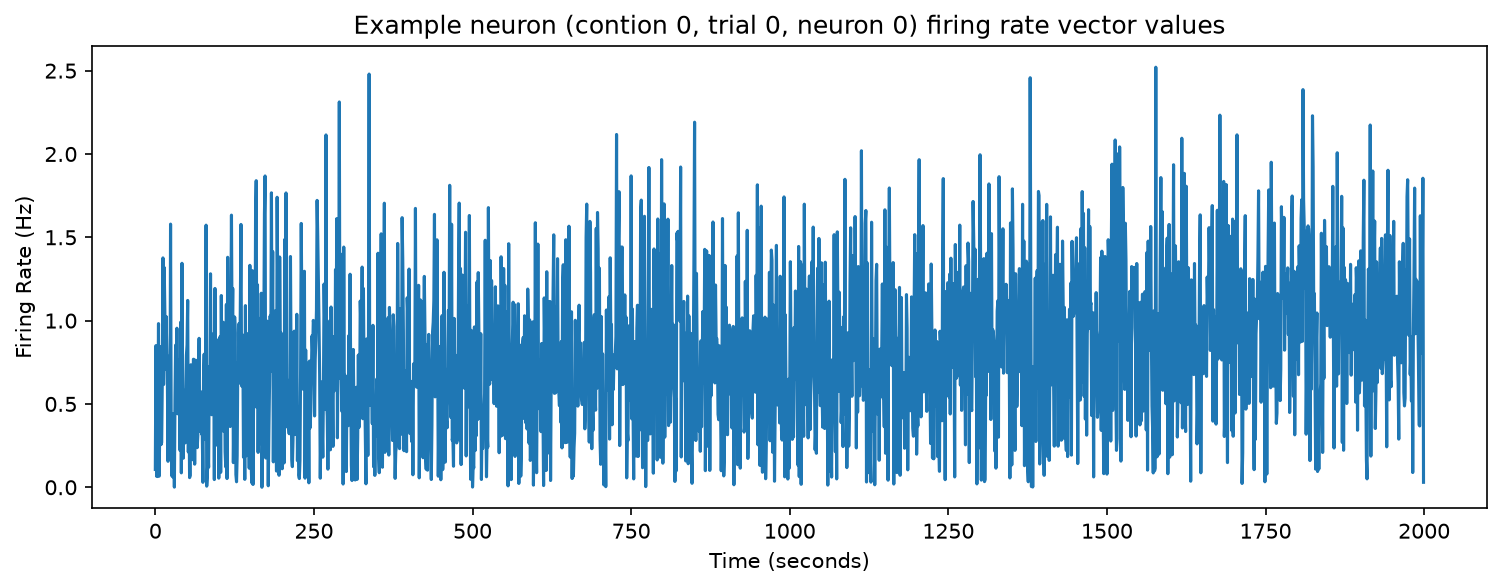

In [11]:
neuron0_rates = arr[0,0,0,:]  # Grabbing the first neuron's timepoints

# Plotting these rates using matplotlib

import matplotlib.pyplot as plt

plt.figure(figsize=(12,4), dpi=150)
plt.plot(neuron0_rates)
plt.xlabel("Time (seconds)")
plt.ylabel("Firing Rate (Hz)")
plt.title("Example neuron (contion 0, trial 0, neuron 0) firing rate vector values")
plt.show()

Again, the shape of our array is organized as `(conditions, trials, neurons, timepoints)`. 

When we call `arr[0,0,0,:]`, we are asking numpy to return the vector correspondint to the specific case of condition 0, trial 0, and neuron 0. 

If we call `arr[0,0,:,:]`, we are asking numpy to return the firing rates of all neurons for condition 0 trial 0, so it will return us a matrix of `(neurons, timepoints)`. 

I will plot this as a heatmap, so you can see the array structure (again, the exact plotting code is irrelevant).

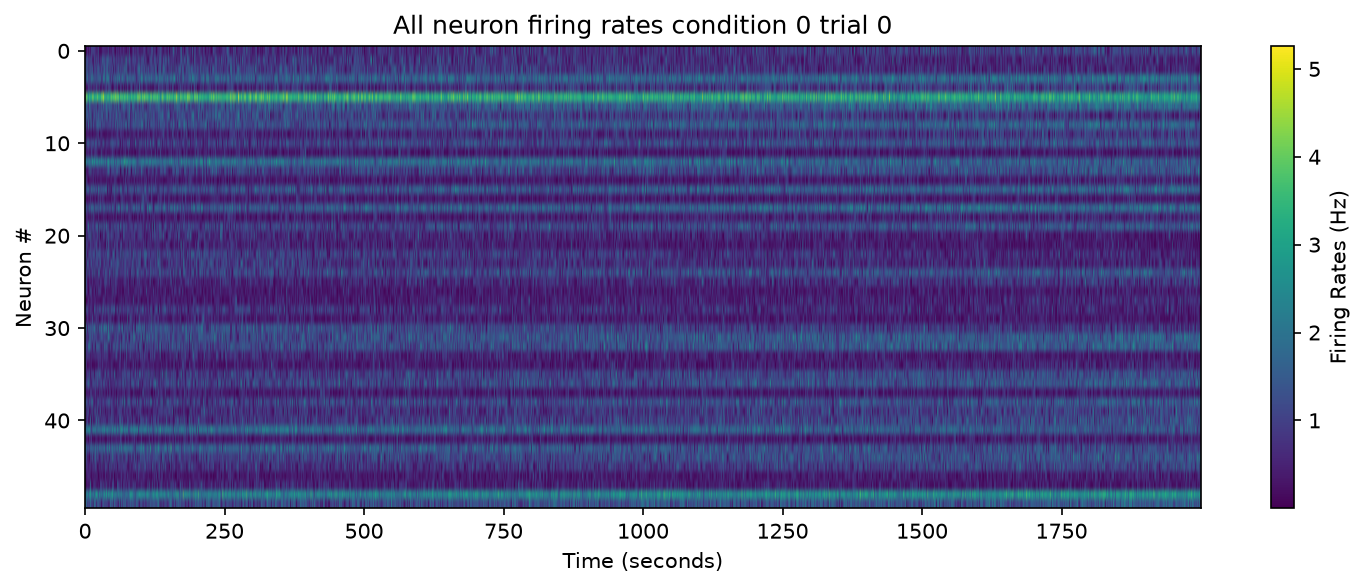

In [15]:
cond_0_trial_0_all_rates = arr[0,0,:,:]

# Plotting these rates using matplotlib

plt.figure(figsize=(12,4), dpi=150)
im = plt.imshow(cond_0_trial_0_all_rates, aspect="auto")
plt.colorbar(im, label="Firing Rates (Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Neuron #")
plt.title("All neuron firing rates condition 0 trial 0")
plt.show()

The neuron # here stands for the rows of our matrix `(neurons, timepoints)`, so each row is a vector we plotted in the previous cell. When we called `array[0,0,:,:]`, we sliced our array to get this specific matrix, but we know that there exists 9 more similar matrices for each trial (10 total) for condition 0. 

Let's plot each of these using a for loop!

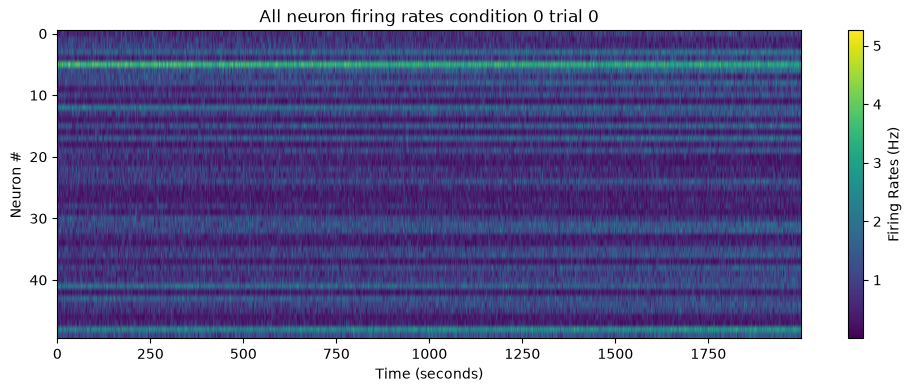

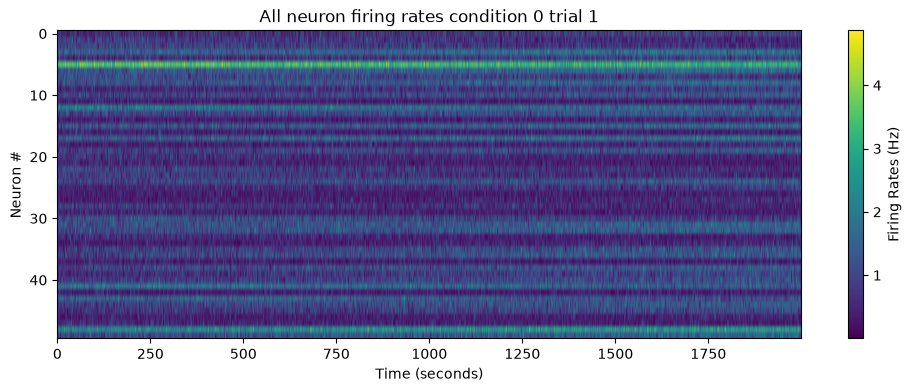

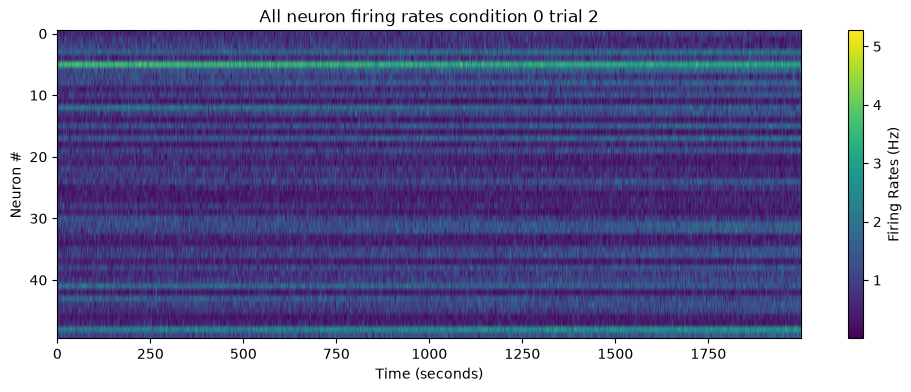

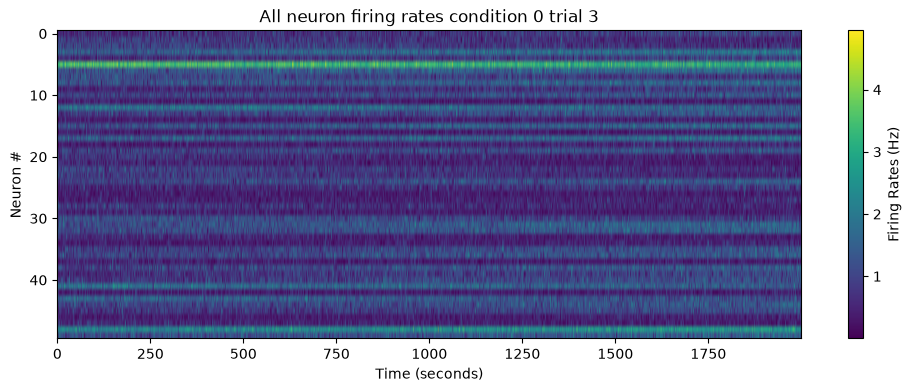

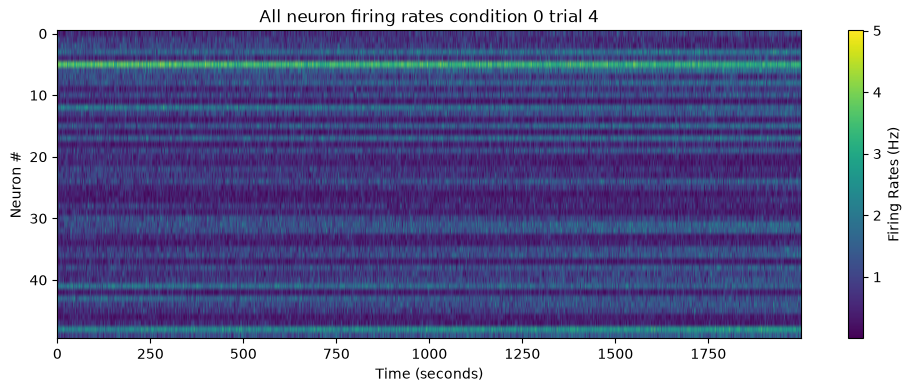

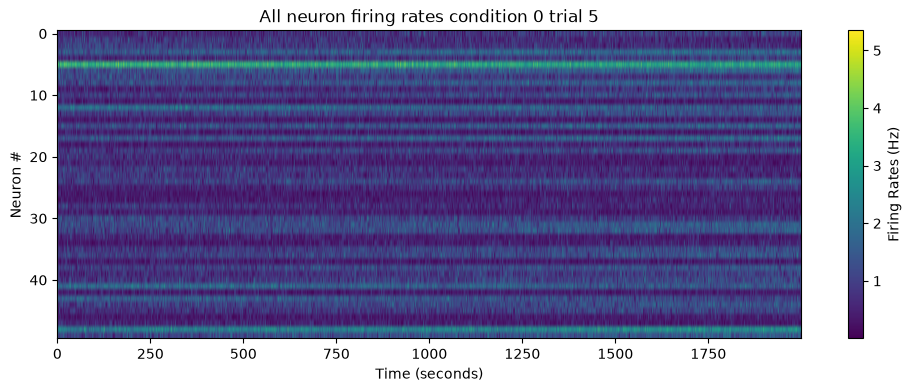

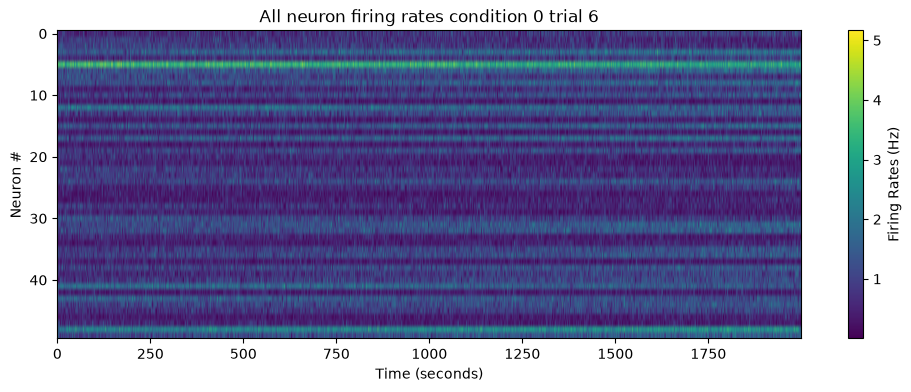

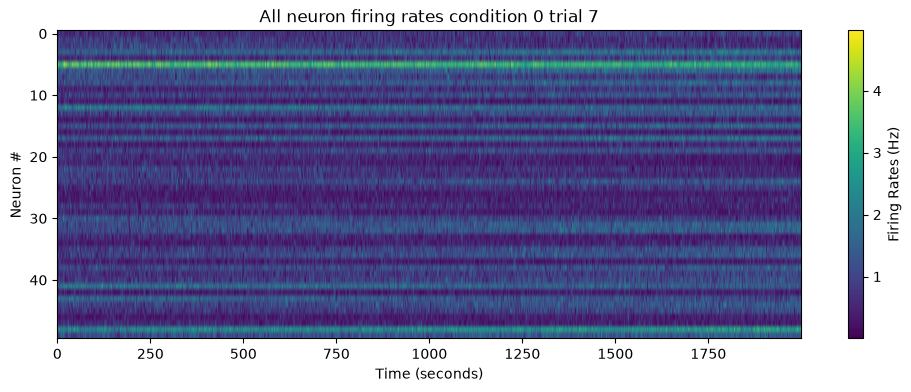

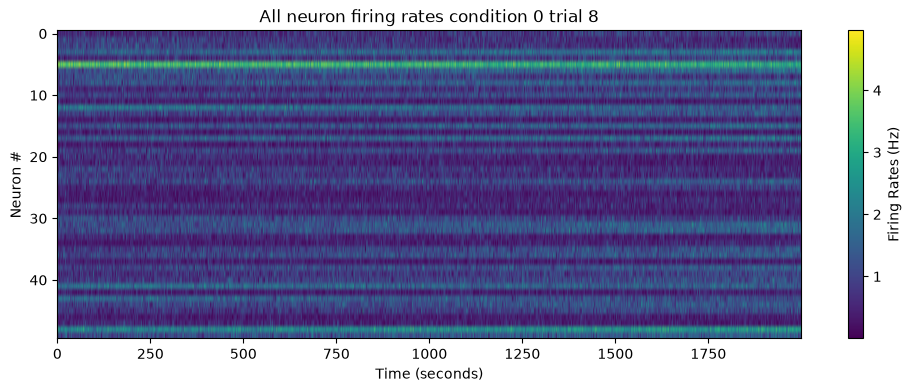

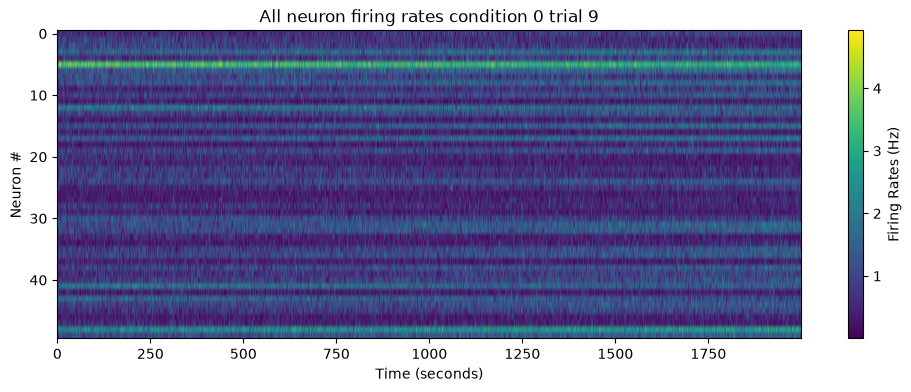

In [17]:
# I'll create a for loop to iterate over the trials dimension

for i in range(arr.shape[1]):   # arr.shape[1] returns 10 since shape is a tuple -> (cond, trials, neurons, timepoints)
    trial_matrix = arr[0,i,:,:]

    # Plotting these rates using matplotlib

    plt.figure(figsize=(12,4), dpi=100)
    im = plt.imshow(trial_matrix, aspect="auto")
    plt.colorbar(im, label="Firing Rates (Hz)")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Neuron #")
    plt.title(f"All neuron firing rates condition 0 trial {i}")   # <-- f string!
    plt.show()

The trial values are not that different from each other which is good since they are trial replicates. More importantly, you can see that each trial is can be represented as a matrix!

We can stipulate that our array is stacking each of these matrices in the third dimension (towards/away from the screen)

Then, if we average across trials, we are collapsing the trials dimension, allowing us to plot the average in 2 dimensions! (Still only on condition 0)

`arr[0,:,:,:]` will return us the 3D array with shape `(trials, neurons, timepoints)`, so we run `.mean(axis=0)

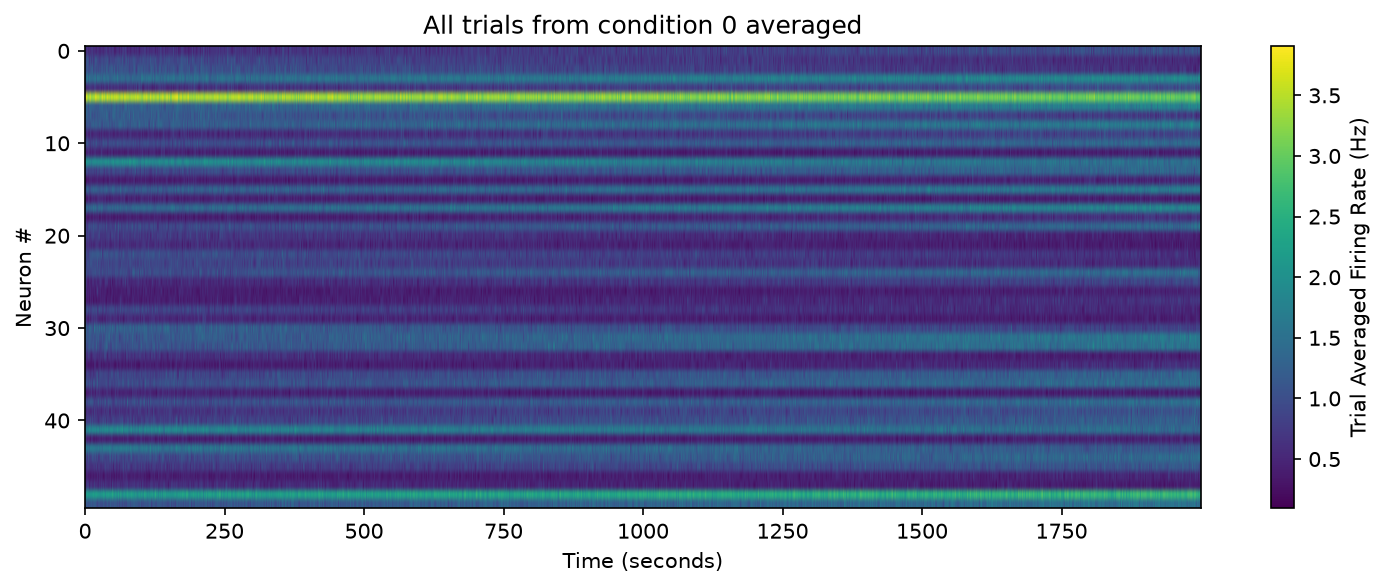

In [ ]:
cond_0_trial_avg = arr[0,:,:,:].mean(axis=0)  # Average all trials from condition 0

# Plotting these rates using matplotlib

plt.figure(figsize=(12,4), dpi=150)
im = plt.imshow(cond_0_trial_avg, aspect="auto")
plt.colorbar(im, label="Trial Averaged Firing Rate (Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Neuron #")
plt.title("All trials from condition 0 averaged")
plt.show()

We now know that for each condition, the information is stored as 3D arrays `(trial, neuron, timepoints)`. We can stack these two arrays (for condition 0 and condition 1) in the fourth dimension, which will give us our original array `(condition, trial, neuron, timepoints)`

I can't show you array 4D array, but I can show you the two trial averages for each condition:

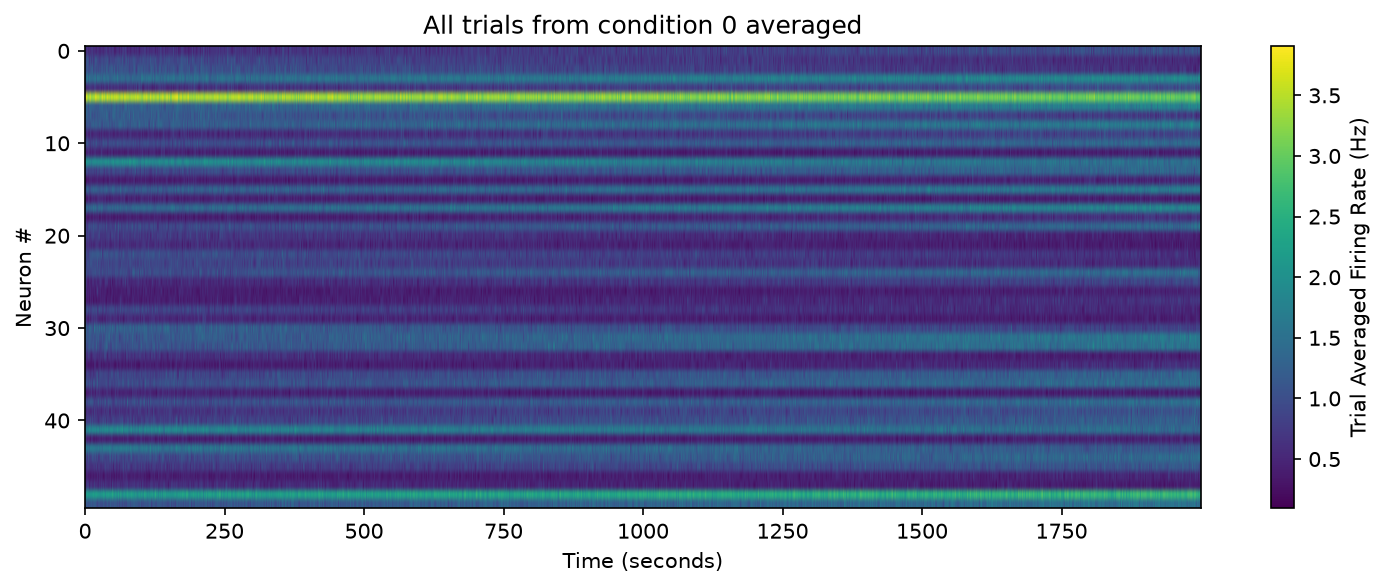

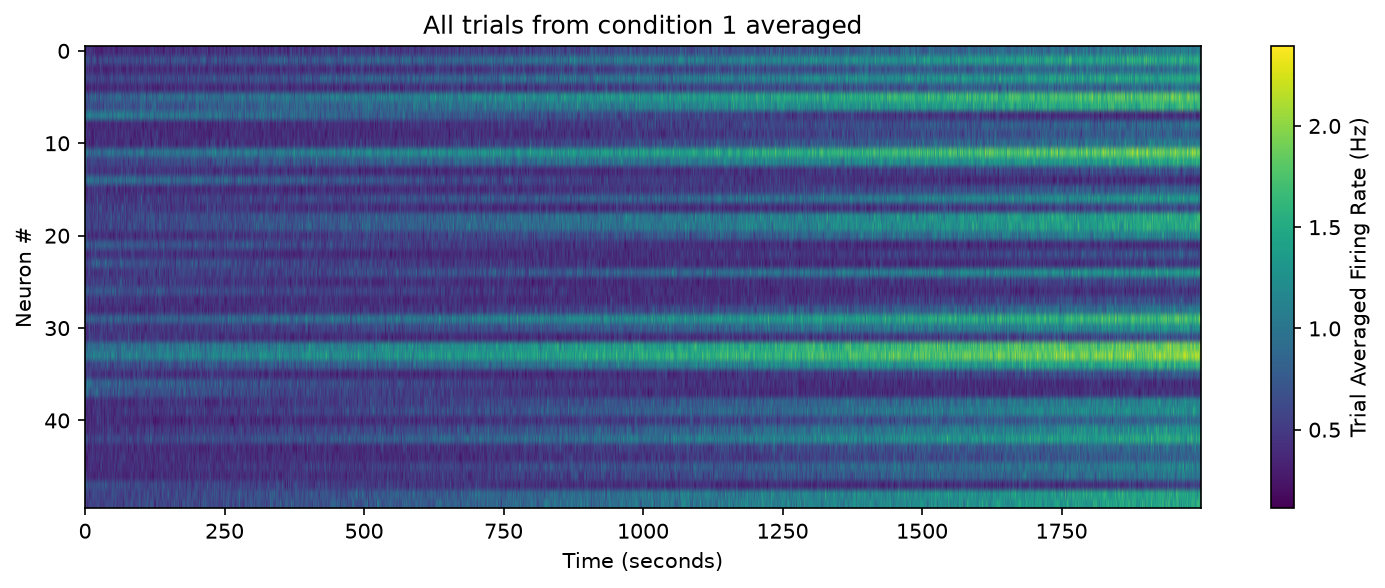

In [20]:
for i in range(arr.shape[0]):
    cond_trial_avg = arr[i,:,:,:].mean(axis=0)  # Average all trials from condition i

    # Plotting these rates using matplotlib

    plt.figure(figsize=(12,4), dpi=150)
    im = plt.imshow(cond_trial_avg, aspect="auto")
    plt.colorbar(im, label="Trial Averaged Firing Rate (Hz)")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Neuron #")
    plt.title(f"All trials from condition {i} averaged")
    plt.show()

This is equivalent to the example where we ran `arr.mean(axis=1)` and plotting the matrices for each condition.